# Hakari — quanto tempo o bairro espera por um reparo?

**Pergunta de ML:** um pedido de reparo de infraestrutura feito ao SP156 vai ser resolvido em até 15 dias?

**Cidadão:** o morador que reporta um buraco, um bueiro entupido, um poste em mau estado ou mato alto
na praça e não sabe quando o problema vai ser resolvido.

**Por que importa para o Hakari:** o SP156 não registra iluminação pública, então ninguém mede quanto
tempo uma rua fica no escuro. Este modelo mede a espera nos reparos que a cidade já registra e mostra
onde ela é maior. O Hakari leva essa medição para os postes, com o próprio poste avisando que apagou.

**Dados:** SP156 - Solicitações, Portal de Dados Abertos da Prefeitura de São Paulo, de 2025T4 a 2026T3
(fonte, links e tratamento em `dados/README.md`).

**Modelo:** XGBoost, classificação binária.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

SEED = 42
N_DIAS = 15
FIGURAS = Path('figuras')
FIGURAS.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 80)

## 1. Dados

O arquivo vem de `preparar_dados.py`, que unifica os quatro CSVs trimestrais (cada um com separador,
codificação e formato de data diferentes) e mantém só os assuntos de reparo físico do tema *Rua e bairro*.

In [2]:
df = pd.read_csv('dados/sp156_rua_e_bairro.csv.gz', parse_dates=['abertura', 'finalizacao', 'data_extracao'])
df['prefeitura'] = df['prefeitura'].fillna('NAO INFORMADA')
df['distrito'] = df['distrito'].fillna('NAO INFORMADO')
print(f'{len(df):,} solicitações'.replace(',', '.'))
df.head()

231.236 solicitações


,abertura,finalizacao,meio,assunto,servico,status,orgao,prefeitura,distrito,trimestre,data_extracao
0,2025-12-23,2026-02-08,MOBILE,Drenagem de água de chuva,Drenagem de água da chuva - Bueiros e bocas de lobo,Cancelada,INTEGRAÇÃO-SMGI/SGZ,ITAQUERA,JOSE BONIFACIO,2025T4,2026-08-07
1,2025-12-23,2025-12-29,MOBILE,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,ITAQUERA,CIDADE LIDER,2025T4,2026-08-07
2,2025-11-15,2025-11-15,MOBILE,Capinação e roçada de áreas verdes,Guias e sarjetas - Solicitar capinação,Finalizada,INTEGRAÇÃO-AMLURB-FLIP,BUTANTA,MORUMBI,2025T4,2026-08-07
3,2025-11-15,2025-11-15,PORTAL,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,CAPELA DO SOCORRO,GRAJAU,2025T4,2026-08-07
4,2025-11-15,2025-11-15,CRM,Praças,Praças - sugerir reforma e revitalização,Finalizada,SMSUB-CPO-Fechamento automatico,ARICANDUVA-FORMOSA-CARRAO,VILA FORMOSA,2025T4,2026-08-07


In [3]:
pd.crosstab(df['assunto'], df['trimestre'], margins=True, margins_name='Total')

trimestre,2025T4,2026T1,2026T2,2026T3,Total
assunto,,,,,
Capinação e roçada de áreas verdes,9924,23773,11590,5928,51215
Drenagem de água de chuva,9656,13123,7850,9073,39702
Fiação e Postes,738,2105,8317,13332,24492
Praças,994,1415,1202,1169,4780
"Reparos em Asfalto, Pontes, Viadutos e Túneis",23797,30940,23427,30173,108337
"Ruas, vilas, vielas e escadarias",523,806,667,714,2710
Total,45632,72162,53053,60389,231236


In [4]:
pd.crosstab(df['status'], df['trimestre'])

trimestre,2025T4,2026T1,2026T2,2026T3
status,,,,
Aberto,2961,12352,14220,19729
Cancelada,196,720,95,72
Em Andamento,6,16,23,24
Finalizada,42469,59074,38715,40564


## 2. Rótulo: resolvido em até 15 dias

Muitos pedidos ainda estavam abertos quando o arquivo foi extraído. Usar só os finalizados ensinaria o
modelo apenas com os casos que já terminaram, que tendem a ser os mais rápidos. A regra abaixo usa a
informação de todos os pedidos cujo resultado já é conhecido:

| Situação na extração | Rótulo |
|---|---|
| Finalizado em até 15 dias | **1** (resolvido no prazo) |
| Finalizado depois de 15 dias | **0** |
| Ainda aberto, com mais de 15 dias de idade | **0** (já passou do prazo, seja qual for o desfecho) |
| Ainda aberto, com 15 dias ou menos | fora: resultado ainda desconhecido |
| Cancelado | fora: não houve reparo |

O limite de 15 dias fica perto da mediana do tempo de atendimento, o que deixa as classes equilibradas.

In [5]:
dias = (df['finalizacao'] - df['abertura']).dt.days
idade = (df['data_extracao'] - df['abertura']).dt.days
finalizado = df['status'].eq('Finalizada') & df['finalizacao'].notna()
aberto = df['status'].isin(['Aberto', 'Em Andamento'])

df['resolvido_no_prazo'] = np.select(
    [finalizado & (dias <= N_DIAS), finalizado & (dias > N_DIAS), aberto & (idade > N_DIAS)],
    [1, 0, 0], default=-1)

print('Tempo de atendimento dos finalizados (dias):')
print(dias[finalizado].describe().round(1).to_string())
pd.crosstab(df['trimestre'], df['resolvido_no_prazo'].map({1: 'no prazo', 0: 'fora do prazo', -1: 'excluído'}))

Tempo de atendimento dos finalizados (dias):


count    180802.0
mean         15.6
std          28.7
min           0.0
25%           1.0
50%           5.0
75%          18.0
max         306.0


resolvido_no_prazo,excluído,fora do prazo,no prazo
trimestre,,,
2025T4,204,11564,33864
2026T1,729,36273,35160
2026T2,98,24224,28731
2026T3,3900,22929,33560


## 3. Variáveis

Só entra o que se sabe **no momento da abertura** do pedido:

- `assunto`, `servico`: o tipo de reparo
- `meio`: canal usado (portal, aplicativo, telefone, chatbot)
- `prefeitura`, `distrito`: onde está o problema
- `dia_semana`: dia da abertura
- `carga_7d`: quantos pedidos de reparo a mesma prefeitura operacional recebeu nos 7 dias anteriores,
  uma medida da fila

Ficam de fora:

- `finalizacao` e `status`: contam o resultado ao modelo (vazamento)
- `orgao`: pode ser reclassificado depois da abertura, segundo o dicionário de dados
- mês: o teste cobre julho a setembro, meses que o treino não tem, então o modelo não teria como aprender o efeito deles

In [6]:
diario = df.groupby(['prefeitura', 'abertura']).size().rename('n').reset_index()
carga = (diario.set_index('abertura')
         .groupby('prefeitura')['n']
         .apply(lambda s: s.asfreq('D', fill_value=0).rolling(7, min_periods=1).sum().shift(1, fill_value=0))
         .rename('carga_7d')
         .reset_index())
df = df.merge(carga, on=['prefeitura', 'abertura'], how='left')
df['dia_semana'] = df['abertura'].dt.dayofweek

CATEGORICAS = ['assunto', 'servico', 'meio', 'prefeitura', 'distrito']
NUMERICAS = ['dia_semana', 'carga_7d']
for col in CATEGORICAS:
    df[col] = df[col].astype('category')

df[CATEGORICAS + NUMERICAS].nunique()

assunto         6
servico        28
meio            5
prefeitura     39
distrito       97
dia_semana      7
carga_7d      440
dtype: int64

## 4. Divisão treino/teste

A divisão é **temporal**: o modelo treina com os pedidos de outubro/2025 a junho/2026 e é testado com
os de julho a setembro/2026. É o uso real: prever pedidos futuros a partir do passado. Uma divisão
aleatória misturaria pedidos da mesma semana e da mesma rua nos dois lados e daria um resultado otimista.

In [7]:
rotulados = df[df['resolvido_no_prazo'] >= 0]
treino = rotulados[rotulados['trimestre'] != '2026T3']
teste = rotulados[rotulados['trimestre'] == '2026T3']

X_treino, y_treino = treino[CATEGORICAS + NUMERICAS], treino['resolvido_no_prazo']
X_teste, y_teste = teste[CATEGORICAS + NUMERICAS], teste['resolvido_no_prazo']

pd.DataFrame({
    'pedidos': [len(treino), len(teste)],
    '% no prazo': [y_treino.mean() * 100, y_teste.mean() * 100],
}, index=['treino (2025T4 a 2026T2)', 'teste (2026T3)']).round(1)

,pedidos,% no prazo
treino (2025T4 a 2026T2),169816,57.6
teste (2026T3),56489,59.4


## 5. Modelo e busca de hiperparâmetros

**Por que XGBoost:** os dados são tabulares, a maioria das variáveis é categórica (há centenas de
distritos e serviços) e o efeito delas não é linear: o mesmo serviço pode ser rápido numa região e lento
em outra. Árvores com boosting capturam essas interações, lidam com categorias de forma nativa e são
o modelo de referência para esse tipo de dado.

**Busca:** 3 × 3 × 2 = **18 combinações** de três hiperparâmetros, com validação cruzada **só no
conjunto de treino**. O teste fica guardado até o fim.

- `max_depth`: profundidade de cada árvore (complexidade)
- `learning_rate`: quanto cada árvore corrige as anteriores
- `n_estimators`: número de árvores

**Validação cruzada temporal.** A validação segue a mesma lógica do teste, sempre do passado para o
futuro, dentro do treino:

| Partição | Treina com | Valida com |
|---|---|---|
| 1 | 2025T4 | 2026T1 |
| 2 | 2025T4 + 2026T1 | 2026T2 |

Uma validação cruzada aleatória (5 partes estratificadas) também foi testada e se mostrou otimista
demais; a comparação está logo depois da busca.

In [8]:
trimestre_treino = treino['trimestre'].to_numpy()
particoes = [
    (np.where(trimestre_treino == '2025T4')[0], np.where(trimestre_treino == '2026T1')[0]),
    (np.where(np.isin(trimestre_treino, ['2025T4', '2026T1']))[0], np.where(trimestre_treino == '2026T2')[0]),
]

modelo = XGBClassifier(tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                       eval_metric='logloss', random_state=SEED, n_jobs=-1)
grade = {
    'max_depth': [3, 6, 10],
    'learning_rate': [0.03, 0.1, 0.3],
    'n_estimators': [100, 300],
}
busca = GridSearchCV(modelo, grade, scoring={'roc_auc': 'roc_auc', 'f1': 'f1'}, refit='roc_auc',
                     cv=particoes, return_train_score=True, n_jobs=1)
busca.fit(X_treino, y_treino)
print('Melhor combinação:', busca.best_params_)

Melhor combinação: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}


In [9]:
resultados = pd.DataFrame(busca.cv_results_)
tabela = resultados[['param_max_depth', 'param_learning_rate', 'param_n_estimators',
                     'mean_train_roc_auc', 'mean_test_roc_auc', 'mean_train_f1', 'mean_test_f1']].copy()
tabela.columns = ['max_depth', 'learning_rate', 'n_estimators',
                  'AUC treino', 'AUC validação', 'F1 treino', 'F1 validação']
tabela['diferença AUC'] = tabela['AUC treino'] - tabela['AUC validação']
tabela.sort_values('AUC validação', ascending=False).round(4).reset_index(drop=True)

,max_depth,learning_rate,n_estimators,AUC treino,AUC validação,F1 treino,F1 validação,diferença AUC
0,6,0.10,100,0.8552,0.7063,0.8534,0.6821,0.1489
1,3,0.30,100,0.8427,0.7061,0.8486,0.6826,0.1365
2,6,0.03,300,0.8510,0.7048,0.8522,0.6814,0.1462
3,10,0.03,300,0.9061,0.7041,0.8775,0.6777,0.2020
4,10,0.10,100,0.9146,0.7041,0.8827,0.6771,0.2104
5,10,0.03,100,0.8794,0.7037,0.8646,0.6810,0.1757
6,3,0.30,300,0.8624,0.7018,0.8569,0.6790,0.1606
7,3,0.10,300,0.8427,0.7016,0.8483,0.6826,0.1411
8,6,0.10,300,0.8930,0.7015,0.8709,0.6789,0.1914
9,3,0.03,300,0.8195,0.6999,0.8409,0.6845,0.1196


### Por que não a validação aleatória

A mesma combinação avaliada com 5 partes aleatórias estratificadas dá uma AUC bem maior. Pedidos da mesma
semana, rua e equipe caem dos dois lados da divisão, e o modelo é premiado por reconhecer um período que já
viu, não por prever o futuro. A estimativa temporal fica bem mais perto do que o modelo entrega no teste.

In [10]:
from sklearn.model_selection import cross_val_score

aleatoria = cross_val_score(XGBClassifier(**busca.best_estimator_.get_params()), X_treino, y_treino,
                            scoring='roc_auc', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
pd.Series({
    'validação aleatória (5 partes)': aleatoria.mean(),
    'validação temporal (2 partições)': busca.best_score_,
}, name='AUC estimada').round(4).to_frame()

,AUC estimada
validação aleatória (5 partes),0.8016
validação temporal (2 partições),0.7063


### Overfitting

A diferença entre a AUC no treino e na validação mede o quanto o modelo decora o treino. O gráfico mostra
essa diferença crescendo com a profundidade das árvores.

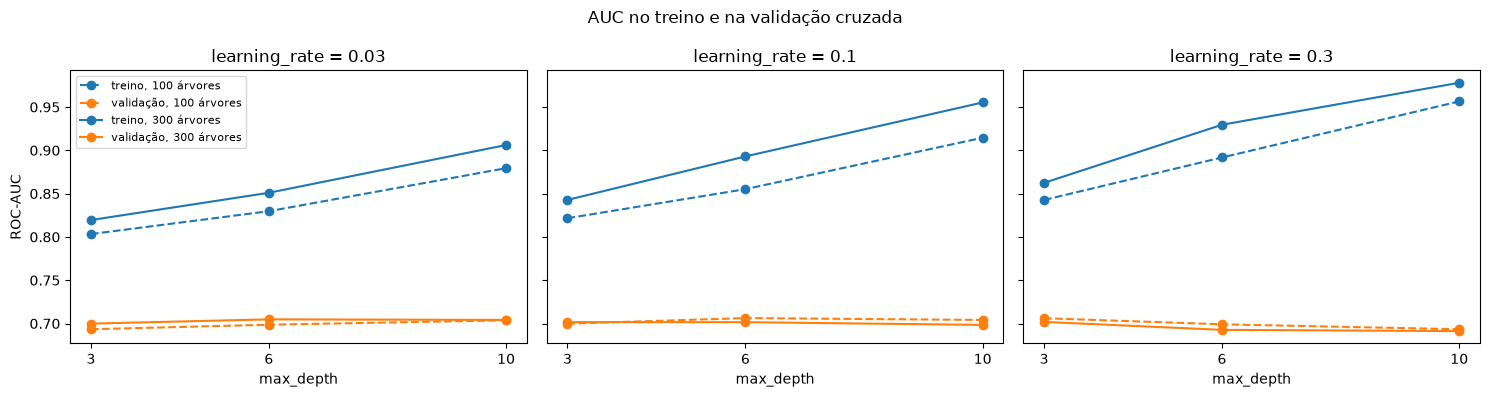

In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eixo, lr in zip(eixos, grade['learning_rate']):
    for n, estilo in zip(grade['n_estimators'], ['--', '-']):
        parte = tabela[(tabela['learning_rate'] == lr) & (tabela['n_estimators'] == n)].sort_values('max_depth')
        eixo.plot(parte['max_depth'], parte['AUC treino'], 'o' + estilo, color='tab:blue', label=f'treino, {n} árvores')
        eixo.plot(parte['max_depth'], parte['AUC validação'], 'o' + estilo, color='tab:orange', label=f'validação, {n} árvores')
    eixo.set_title(f'learning_rate = {lr}')
    eixo.set_xlabel('max_depth')
    eixo.set_xticks(grade['max_depth'])
eixos[0].set_ylabel('ROC-AUC')
eixos[0].legend(fontsize=8)
fig.suptitle('AUC no treino e na validação cruzada')
fig.tight_layout()
fig.savefig(FIGURAS / 'overfitting.png', dpi=120)
plt.show()

## 6. Resultados no treino e no teste

O melhor modelo da busca é retreinado com todo o treino e avaliado uma única vez no teste. A linha de
base é um classificador que sempre responde a classe mais comum do treino.

In [12]:
melhor = busca.best_estimator_

def metricas(y, probabilidade):
    previsto = (probabilidade >= 0.5).astype(int)
    return {
        'acurácia': accuracy_score(y, previsto),
        'precisão': precision_score(y, previsto, zero_division=0),
        'recall': recall_score(y, previsto, zero_division=0),
        'F1': f1_score(y, previsto, zero_division=0),
        'ROC-AUC': roc_auc_score(y, probabilidade) if len(set(probabilidade)) > 1 else 0.5,
    }

classe_comum = int(y_treino.mean() >= 0.5)
comparacao = pd.DataFrame({
    'XGBoost — treino': metricas(y_treino, melhor.predict_proba(X_treino)[:, 1]),
    'XGBoost — teste': metricas(y_teste, melhor.predict_proba(X_teste)[:, 1]),
    'linha de base — teste': metricas(y_teste, np.full(len(y_teste), float(classe_comum))),
}).round(4)
comparacao

,XGBoost — treino,XGBoost — teste,linha de base — teste
acurácia,0.7366,0.6716,0.5941
precisão,0.7508,0.7342,0.5941
recall,0.8119,0.7011,1.0000
F1,0.7801,0.7173,0.7454
ROC-AUC,0.8164,0.7425,0.5000


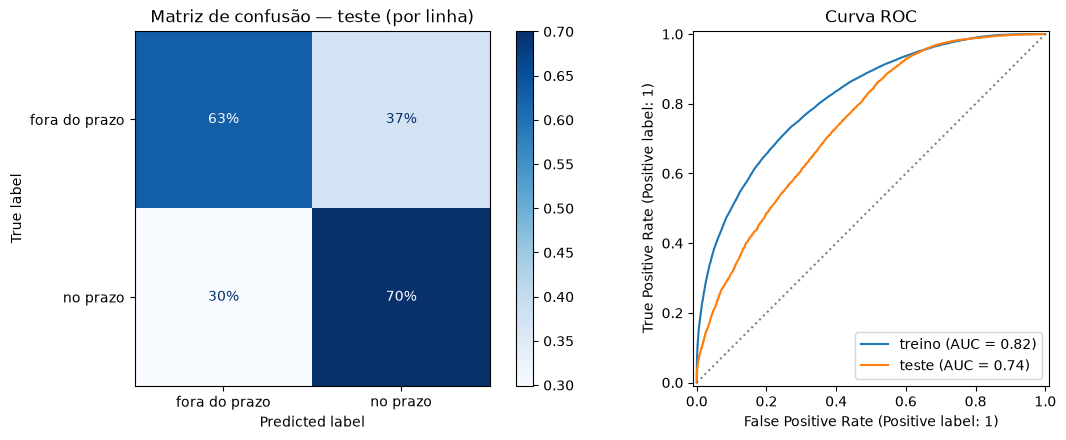

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(melhor, X_teste, y_teste, display_labels=['fora do prazo', 'no prazo'],
                                      normalize='true', values_format='.0%', cmap='Blues', ax=eixos[0])
eixos[0].set_title('Matriz de confusão — teste (por linha)')
RocCurveDisplay.from_estimator(melhor, X_treino, y_treino, name='treino', ax=eixos[1])
RocCurveDisplay.from_estimator(melhor, X_teste, y_teste, name='teste', ax=eixos[1])
eixos[1].plot([0, 1], [0, 1], ':', color='gray')
eixos[1].set_title('Curva ROC')
fig.tight_layout()
fig.savefig(FIGURAS / 'matriz_roc.png', dpi=120)
plt.show()

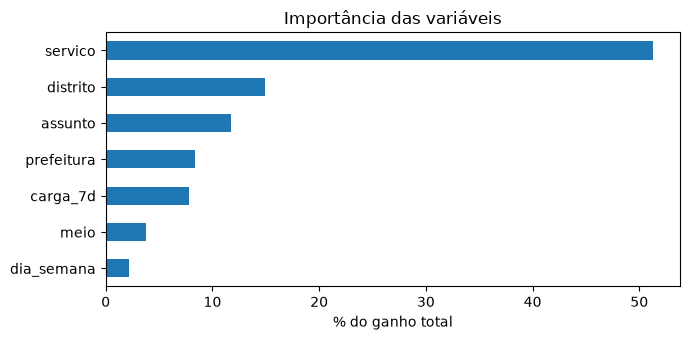

In [14]:
importancia = (pd.Series(melhor.get_booster().get_score(importance_type='gain'))
               .reindex(CATEGORICAS + NUMERICAS).fillna(0).sort_values())
ax = (importancia / importancia.sum() * 100).plot.barh(figsize=(7, 3.5), color='tab:blue')
ax.set_xlabel('% do ganho total')
ax.set_title('Importância das variáveis')
plt.tight_layout()
plt.savefig(FIGURAS / 'importancia.png', dpi=120)
plt.show()

## 7. Leitura para o cidadão

No período de teste, quanto a chance de um reparo sair em até 15 dias varia de uma região para outra?

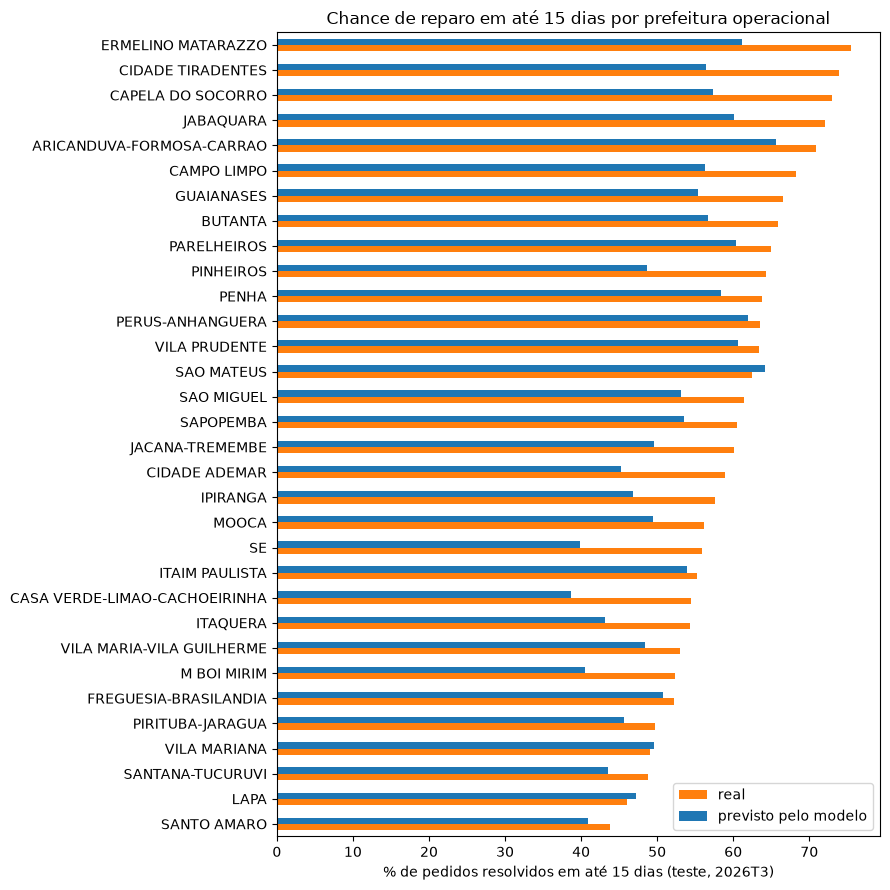

,pedidos,real,previsto
prefeitura,,,
SANTO AMARO,1490,43.8,40.900002
LAPA,1883,46.1,47.299999
SANTANA-TUCURUVI,1695,48.8,43.500000
VILA MARIANA,1694,49.1,49.500000
PIRITUBA-JARAGUA,2362,49.7,45.599998
ARICANDUVA-FORMOSA-CARRAO,2098,70.9,65.699997
JABAQUARA,862,72.0,60.099998
CAPELA DO SOCORRO,2559,73.0,57.400002
CIDADE TIRADENTES,622,74.0,56.500000


In [15]:
teste_regiao = teste.assign(prob=melhor.predict_proba(X_teste)[:, 1])
por_regiao = (teste_regiao.groupby('prefeitura', observed=True)
              .agg(pedidos=('prob', 'size'), real=('resolvido_no_prazo', 'mean'), previsto=('prob', 'mean')))
por_regiao = por_regiao[por_regiao['pedidos'] >= 300].sort_values('real')
por_regiao[['real', 'previsto']] *= 100

ax = por_regiao[['real', 'previsto']].plot.barh(figsize=(9, 9), color=['tab:orange', 'tab:blue'])
ax.set_xlabel('% de pedidos resolvidos em até 15 dias (teste, 2026T3)')
ax.set_ylabel('')
ax.legend(['real', 'previsto pelo modelo'])
ax.set_title('Chance de reparo em até 15 dias por prefeitura operacional')
plt.tight_layout()
plt.savefig(FIGURAS / 'por_regiao.png', dpi=120)
plt.show()
por_regiao.round(1).iloc[np.r_[0:5, -5:0]]

In [16]:
por_assunto = (teste_regiao.groupby('assunto', observed=True)
               .agg(pedidos=('prob', 'size'), real=('resolvido_no_prazo', 'mean'), previsto=('prob', 'mean')))
por_assunto[['real', 'previsto']] *= 100
por_assunto.sort_values('real').round(1)

,pedidos,real,previsto
assunto,,,
Fiação e Postes,12220,27.9,19.200001
"Ruas, vilas, vielas e escadarias",680,50.4,42.000000
"Reparos em Asfalto, Pontes, Viadutos e Túneis",28011,66.1,56.200001
Drenagem de água de chuva,8665,67.2,64.599998
Praças,1140,78.8,82.000000
Capinação e roçada de áreas verdes,5773,79.3,69.599998



## 8. Conclusão

**O modelo.** O XGBoost escolhido pela validação temporal (`max_depth=6`, `learning_rate=0.1`,
`n_estimators=100`) chega a **ROC-AUC de 0,74 no teste**, contra 0,50 de um palpite, e acerta 67% dos
pedidos, contra 59% da linha de base que sempre responde "no prazo". O F1 da linha de base é maior
(0,75 contra 0,72) só porque ela diz "sim" para tudo e nunca erra um pedido rápido; ela não separa nada.

**Overfitting.** A AUC cai de 0,82 no treino para 0,74 no teste. Parte disso é o modelo decorando o
treino, o que o gráfico mostra crescendo com `max_depth`: na profundidade 10 o treino passa de 0,95 e a
validação não melhora. A outra parte é mudança no tempo: no 3º trimestre de 2026 a cidade resolveu
pedidos mais rápido do que no período de treino, e o modelo subestima o resultado real em quase todas as
regiões. A validação aleatória esconderia os dois efeitos (estimaria 0,80); a temporal estimou 0,71,
perto do que o modelo entregou.

**Para o cidadão.**

- **O endereço pesa.** Entre julho e setembro de 2026, um pedido de reparo em Ermelino Matarazzo teve
  76% de chance de sair em até 15 dias; em Santo Amaro, 44%. O mesmo pedido pode levar o dobro do tempo
  conforme a região.
- **Postes e fiação são o pior caso.** Só 28% dos pedidos de "Fiação e postes" foram resolvidos em até
  15 dias, contra 66% dos tapa-buracos e 79% das capinações.
- **O tipo de serviço é o que mais explica a espera** (metade do ganho do modelo), seguido do distrito.

**Para o Hakari.** O SP156 não tem nem registro de lâmpada apagada, e o que existe sobre postes é a
categoria mais lenta da cidade. O Hakari ataca exatamente esse ponto: o poste avisa sozinho que falhou,
a ocorrência nasce no minuto da falha e não quando alguém decide reclamar, e a prefeitura passa a ter o
dado que hoje não existe. Um modelo como este pode então priorizar a fila da manutenção pelas regiões e
serviços com maior risco de atraso.

**Limitações.** O SP156 registra pedidos, não problemas; os assuntos são reclassificados entre
relatórios; e o modelo não tem variáveis de clima ou de capacidade das equipes, que provavelmente
explicam boa parte do que ele ainda erra.
